## Cheung Method


2026/3/17

Extracted SBH by Cheung Methods

Inspired by qwen3.5


1. 物理背景與公式根據熱電子發射理論（Thermionic Emission Theory），流經肖特基接面的電流 $I$
   根據熱電子發射理論，電流公式為：$$I = AA^*T^2 \exp\left( \frac{-q\Phi_b}{kT} \right) \exp\left( \frac{q(V - IR_s)}{nkT} \right)$$當我們對兩邊取對數並整理 $V$ 時，會得到：$$V = IR_s + n\Phi_b + \frac{nkT}{q} \ln\left( \frac{I}{AA^*T^2} \right)$$這時候定義 $H(I)$：$$H(I) \equiv V - \left( \frac{nkT}{q} \right) \ln\left( \frac{I}{AA^*T^2} \right)$$將上面的 $V$ 代入，公式會簡化為：$$H(I) = n\Phi_b + IR_s$$

   其中 $I_s$ 為飽和電流，$R_s$ 是中性區與接觸產生的串聯電阻。當 $V > 3kT/q$ 時，Cheung 提出了兩個函數來線性化處理數據。
---

### Method A, B

I. 函數 A：提取 $R_s$ 與 $n$定義函數 $H(I)$ 如下：$$H(I) = V - \left( \frac{nkT}{q} \right) \ln\left( \frac{I}{AA^*T^2} \right)$$經過推導，可得線性關係式：$$H(I) = n\Phi_b + IR_s$$

II. 函數 B：輔助驗證定義另一個函數 $dV/d(\ln I)$：$$\frac{dV}{d(\ln I)} = \frac{nkT}{q} + IR_s$$

1. 第一步：繪製 $\frac{dV}{d(\ln I)}$ vs. $I$ 圖斜率 (Slope): 代表串聯電阻 $R_s$。截距 (Intercept): 代表 $\frac{nkT}{q}$，由此可計算出理想因子 $n$。這一步不依賴能障高度，因此非常穩定。
2. 第二步：繪製 $H(I)$ vs. $I$ 圖利用第一步得到的 $n$，計算出每個電流點對應的 $H(I)$。斜率 (Slope): 同樣代表 $R_s$（可用來與第一步比對，增加準確性）。截距 (Intercept): 代表 $n\Phi_b$，由此計算出能障高度 $\Phi_b$。

In [2]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

from ivs_tools import HDF5Analyzer, SchottkyAnalyzer, ConfigLoader
from ivs_tools.viz.cheung_diagnostic import plot_fitting_diagnostic

# ## Step 1: 載入數據
root_path = '/home/tim/Documents/AS/data/nanonis2/2024/20240508/2 um 100 pix bias spec map2'
filename = "2 um 100 pix bias spec map2.h5"
h5map_path = Path(root_path) / filename

h5map = HDF5Analyzer(str(h5map_path))
print(f"📁 Loaded: {h5map.metadata.x_pixels}×{h5map.metadata.y_pixels} pixels")

# 查看結構
h5map.list_structure()

# 取得摘要
print("\nSummary:")
summary = h5map.summary()

# 設置 matplotlib 使用 Arial 字體
plt.rcParams.update({
    'font.family': 'Arial',
    'font.size': 12,
    'axes.labelsize': 18,
    'axes.titlesize': 18,
    'axes.titleweight': 'bold',
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 12,
    'figure.titlesize': 20,
    'figure.titleweight': 'bold'
})

📁 Loaded: 100×100 pixels
DATASET: bias (Shape: (500,), Dtype: float64)
DATASET: current_fwd (Shape: (500, 10000), Dtype: float64)

METADATA:
  Experiment: Bias-Spectroscopy-Current-Map-fwd
  Bias Points: 500
  Pixels: 100 x 100
  Range: 2.00e-06 x 2.00e-06 m

Summary:
📋 數據摘要
----------------------------------------
文件: 2 um 100 pix bias spec map2.h5
路徑: /home/tim/Documents/AS/data/nanonis2/2024/20240508/2 um 100 pix bias spec map2/2 um 100 pix bias spec map2.h5

📐 空間維度:
  X方向像素: 100
  Y方向像素: 100

⚡ 偏壓維度:
  偏壓點數: 500
  偏壓範圍: -2.000 到 2.000 V

💾 數據陣列:
  Current Map: (500, 10000) (float64)
    總大小: 38.15 MB
    範圍: -4.328e-05 到 3.409e-05 A
  Bias Vector: (500,) (float64)
----------------------------------------


### Step 2: 初始化 Analyzer (三種方式)

In [3]:
# 方式 1: 完全從 YAML 載入
analyzer = SchottkyAnalyzer()
analyzer.print_config_summary()

# 方式 2: 只覆蓋面積
# analyzer = SchottkyAnalyzer(area_cm2=ConfigLoader.get_area('cafm_tip_10nm'))

# 方式 3: 完全自訂
# analyzer = SchottkyAnalyzer(area_cm2=1e-12, temperature=350, a_star=60, load_from_yaml=False)

🔬 SchottkyAnalyzer Configuration
   Area: 7.854e-13 cm²
   Temperature: 300.0 K
   A**: 54.0 A/cm²/K²
   Layer type: multilayer
   V_T: 0.0259 V
   Window: 50 pts
   n range: [0.5, 2.5]
   min R²: 0.9


### Step 3: 執行擬合

In [4]:
x, y = 75, 71
spec = h5map.get_spectrum_at_pixel(x, y)[3:]
bias = h5map.bias_vector[3:]

result = analyzer.fit_pixel(bias, spec, layer_type="monolayer")

if result.success:
    print(f"✅ Pixel ({x},{y}): ΦB={result.phi_b:.3f} eV, n={result.n:.2f}, R²={result.r_squared:.4f}")
else:
    print(f"❌ Failed: {result.warning}")


✅ Pixel (75,71): ΦB=0.151 eV, n=1.41, R²=0.9461



### ✅ FITTING SUCCESS - Pixel (75, 71)

| Parameter | Value |
|-----------|-------|
| **ΦB (SBH)** | 0.166 eV |
| **n (ideality)** | 2.93 |
| **Rs (series resistance)** | 6.57e+03 Ω |
| **R²** | 0.9970 |
| **Score** | 0.756 |

**Fit Range:** 0.46 ~ 0.65 V

**Statistics:**
- Total windows scanned: 72
- Monotonic fail: 45
- R² pre-filter fail: 13
- Constraint fail: 3
- R² final fail: 0
- Rs mismatch: 0
- ✅ **Passed all checks: 11**


💾 Diagnostic plot saved: analysis_results/schottky_plots/pixel_75_71_diagnostic.png


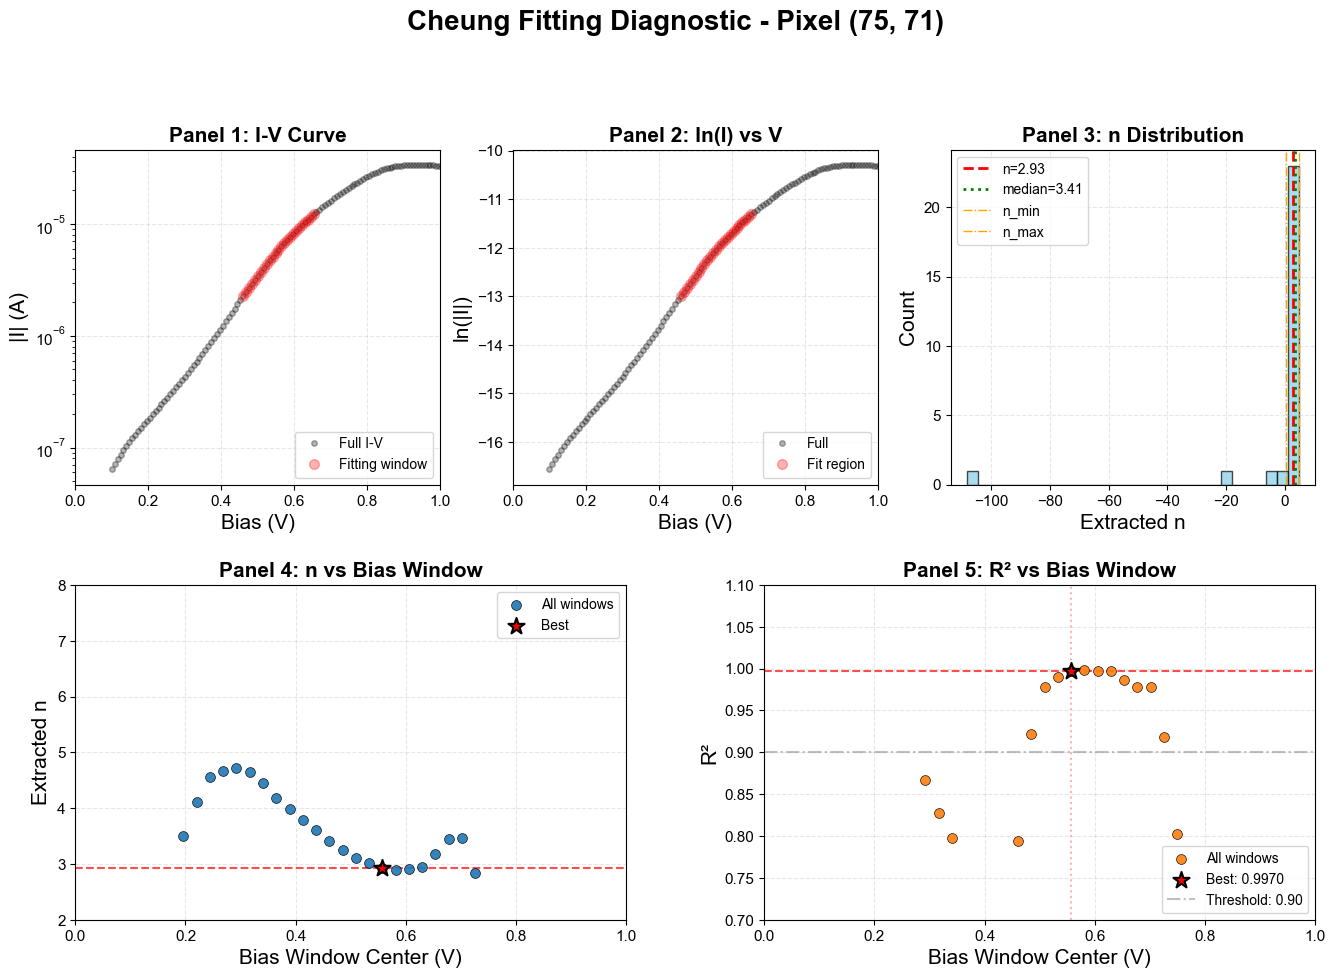

In [6]:
# %% Step 4: 診斷可視化（Markdown + 圖）
from ivs_tools.viz.cheung_diagnostic import plot_fitting_diagnostic

# 執行擬合
result = analyzer.fit_pixel(bias, spec, layer_type="monolayer", forward_bias_only = True, min_forward_bias = 0.1)

# 顯示診斷（會自動顯示 Markdown 摘要 + 圖）
fig = plot_fitting_diagnostic(
    fitter=analyzer.fitter,
    result=result,  # ✅ 傳入 result
    pixel_coords=(x, y),
    save_path=f"analysis_results/schottky_plots/pixel_{x}_{y}_diagnostic.png",
    xlim_bias=(0, 1),
    show_summary=True  # ← 顯示 Markdown 摘要
)
plt.show()


### ✅ FITTING SUCCESS - Pixel (75, 85)

| Parameter | Value |
|-----------|-------|
| **ΦB (SBH)** | 0.288 eV |
| **n (ideality)** | 3.94 |
| **Rs (series resistance)** | 1.16e+04 Ω |
| **R²** | 0.9011 |
| **Score** | 0.581 |

**Fit Range:** 1.49 ~ 1.69 V

**Statistics:**
- Total windows scanned: 72
- Monotonic fail: 17
- R² pre-filter fail: 48
- Constraint fail: 6
- R² final fail: 0
- Rs mismatch: 0
- ✅ **Passed all checks: 1**


💾 Diagnostic plot saved: analysis_results/schottky_plots/pixel_75_85_diagnostic.png


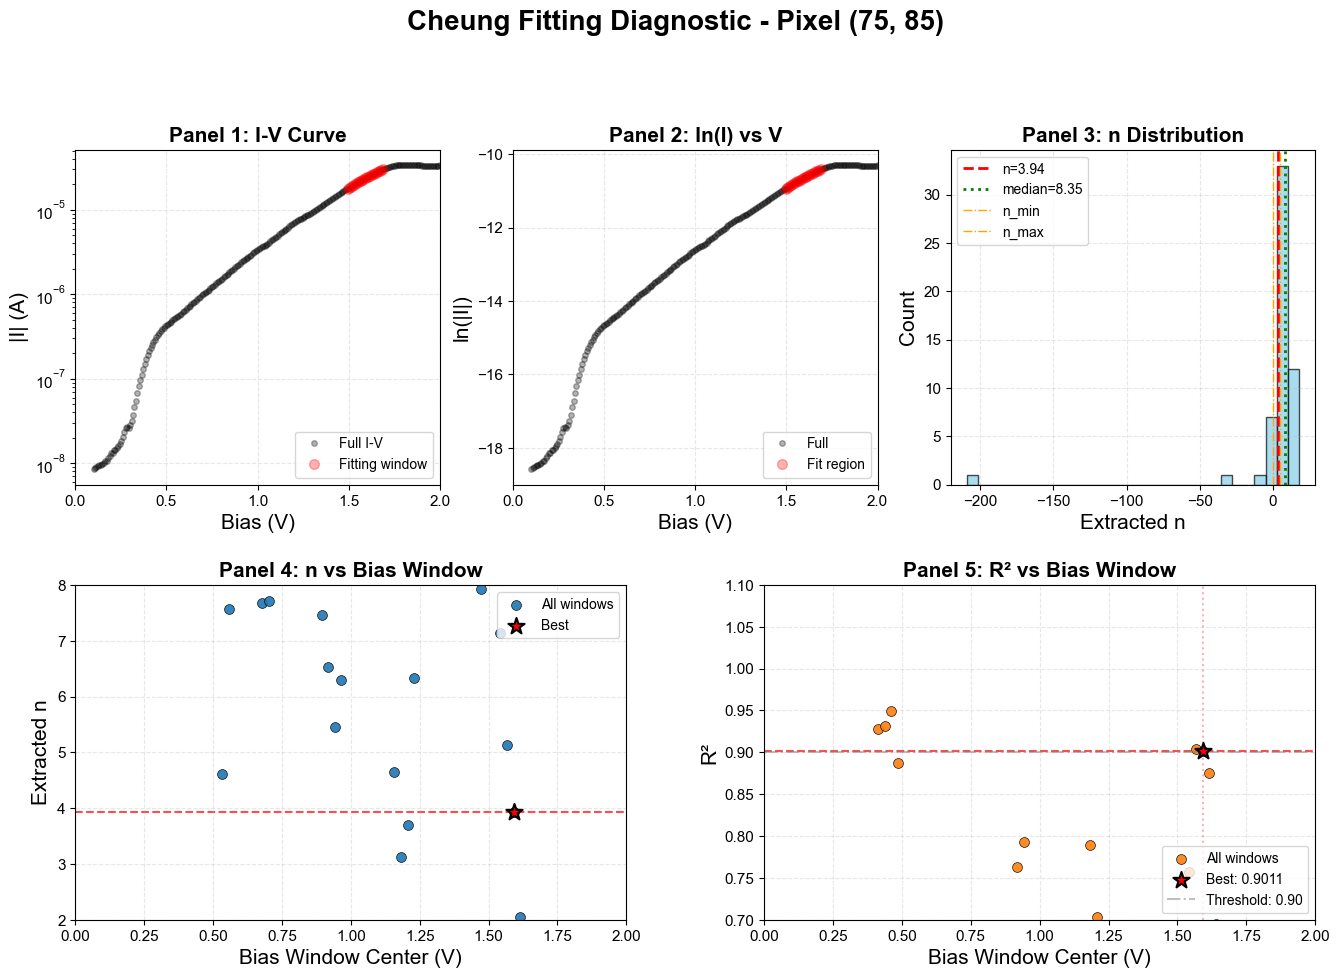

In [10]:
from ivs_tools.viz.cheung_diagnostic import plot_fitting_diagnostic

x, y = (75, 85)
spec = h5map.get_spectrum_at_pixel(x, y)[3:]
bias = h5map.bias_vector[3:]

# 執行擬合
result = analyzer.fit_pixel(bias, spec, layer_type="multilayer", forward_bias_only = True, min_forward_bias = 0.1)

# 顯示診斷（會自動顯示 Markdown 摘要 + 圖）
fig = plot_fitting_diagnostic(
    fitter=analyzer.fitter,
    result=result,  # 
    pixel_coords=(x, y),
    save_path=f"analysis_results/schottky_plots/pixel_{x}_{y}_diagnostic.png",
    xlim_bias=(0, 2),
    show_summary=True  # ← 顯示 Markdown 摘要
)
plt.show()


### ❌ FITTING FAILED - Pixel (76, 84)

**Reason:** 多階段篩選失敗。通過：0/72

**Suggestions:**
- Check data quality (noise, spikes)
- Adjust current_threshold
- Try different layer_type setting
- Consider manual range selection


💾 Diagnostic plot saved: analysis_results/schottky_plots/pixel_76_84_diagnostic.png


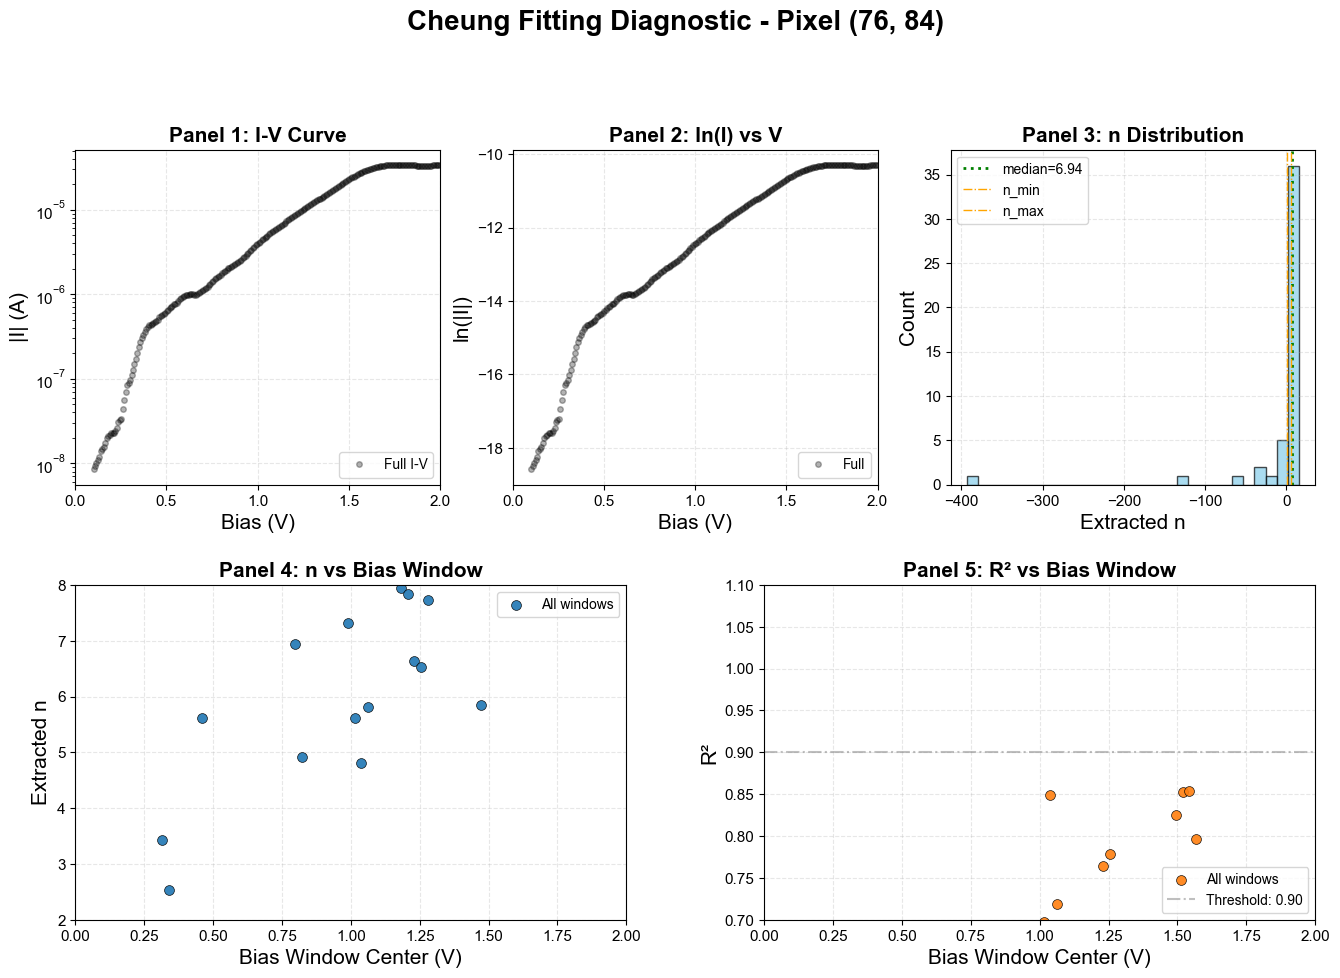

In [18]:
from ivs_tools.viz.cheung_diagnostic import plot_fitting_diagnostic

x, y = (76, 84)
spec = h5map.get_spectrum_at_pixel(x, y)[3:]
bias = h5map.bias_vector[3:]

# 執行擬合
result = analyzer.fit_pixel(bias, spec, layer_type="multilayer", forward_bias_only = True, min_forward_bias = 0.1)

# 顯示診斷（會自動顯示 Markdown 摘要 + 圖）
fig = plot_fitting_diagnostic(
    fitter=analyzer.fitter,
    result=result,  # 
    pixel_coords=(x, y),
    save_path=f"analysis_results/schottky_plots/pixel_{x}_{y}_diagnostic.png",
    xlim_bias=(0, 2),
    show_summary=True  # ← 顯示 Markdown 摘要
)
plt.show()

## Manual

sum of mask manual: 37

✅ 手動擬合結果:
   區間：1.00 ~ 1.30 V
   點數：37
   斜率：3.63 V⁻¹
   R²：0.9957
   n：10.65
   ΦB：0.092 eV


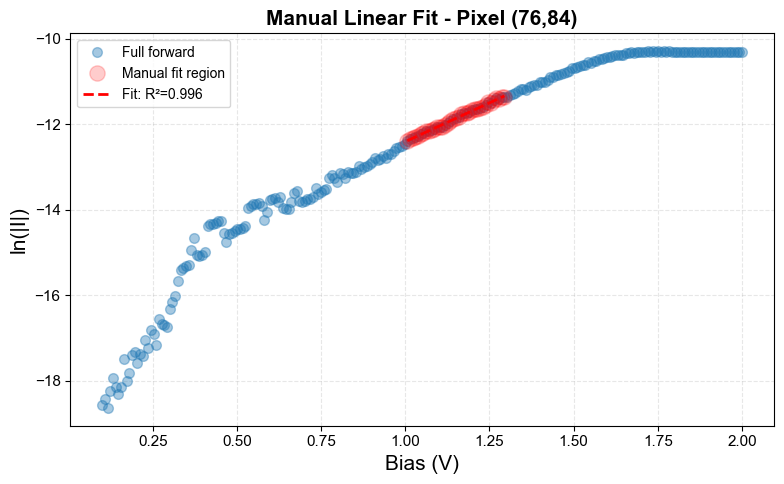

In [20]:
# %% 手動選擇擬合區間（當自動方法都失敗時）
from scipy import stats
import numpy as np
import matplotlib.pyplot as plt

# ── 物理常數定義 ──
q = 1.6021766e-19      # 電子電荷 (C)
k_B_J = 1.380649e-23   # Boltzmann 常數 (J/K)
T = 300.0              # 溫度 (K)
V_T = (k_B_J * T) / q  # 熱電壓 (~0.0259 V @ 300K)

# ── 載入數據 ──
x, y = 76, 84
spec = h5map.get_spectrum_at_pixel(x, y)[3:]
bias = h5map.bias_vector[3:]

# 正向偏壓區
mask_forward = bias > 0.1
bias_fwd = bias[mask_forward]
I_fwd = np.abs(spec[mask_forward])
ln_I_fwd = np.log(I_fwd + 1e-20)

# ── 手動設定線性區範圍（根據上圖觀察調整） ──
V_manual_min = 1.0  # ← 根據圖調整，例如 0.3, 0.4, 0.5...
V_manual_max = 1.3  # ← 根據圖調整，例如 0.6, 0.8, 1.0...

mask_manual = (bias_fwd >= V_manual_min) & (bias_fwd <= V_manual_max)

print(f"sum of mask manual: {np.sum(mask_manual)}")

if np.sum(mask_manual) < 10:
    print(f"⚠️ 手動區間點數不足：{np.sum(mask_manual)} < 10")
    print(f"💡 建議：放寬 V_manual_min 和 V_manual_max 的範圍")
else:
    V_manual = bias_fwd[mask_manual]
    I_manual = I_fwd[mask_manual]
    ln_I_manual = np.log(I_manual + 1e-20)
    
    # 線性擬合
    slope, intercept, r_value, _, _ = stats.linregress(V_manual, ln_I_manual)
    
    # 從斜率計算 n：slope = q/(n*k*T) → n = q/(slope*k*T)
    n_manual = q / (slope * k_B_J * T)
    
    # 計算 ΦB（需要 Richardson constant 和面積）
    area_cm2 = analyzer.area_cm2
    a_star = analyzer.A_star
    I_s = np.exp(intercept)  # 飽和電流
    phi_b_manual = (k_B_J * T / q) * np.log(a_star * area_cm2 * T**2 / I_s)
    
    print(f"\n✅ 手動擬合結果:")
    print(f"   區間：{V_manual_min:.2f} ~ {V_manual_max:.2f} V")
    print(f"   點數：{len(V_manual)}")
    print(f"   斜率：{slope:.2f} V⁻¹")
    print(f"   R²：{r_value**2:.4f}")
    print(f"   n：{n_manual:.2f}")
    print(f"   ΦB：{phi_b_manual:.3f} eV")
    
    fig, ax = plt.subplots(1, 1, figsize=(8, 5))
    ax.plot(bias_fwd, ln_I_fwd, 'o', ms=7, color = 'tab:blue', alpha=0.4, label='Full forward')
    ax.plot(V_manual, ln_I_manual, 'ro', ms=11, alpha=0.2, label='Manual fit region')
    V_fit = np.linspace(V_manual.min(), V_manual.max(), 50)
    ax.plot(V_fit, slope * V_fit + intercept, 'r--', lw=2, label=f'Fit: R²={r_value**2:.3f}')
    ax.set_xlabel('Bias (V)')
    ax.set_ylabel('ln(|I|)')
    ax.set_title(f'Manual Linear Fit - Pixel ({x},{y})')
    ax.legend()
    ax.grid(True, ls='--', alpha=0.3)
    plt.tight_layout()
    plt.show()
    

## Loose fit diagnostics

In [21]:

from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec

# %% 定義寬鬆擬合診斷函數
from matplotlib.gridspec import GridSpec
from IPython.display import display, Markdown

def plot_loose_fit_diagnostic(fitter, result, pixel_coords, bias_original, spec_original,
                             save_path=None):
    """
    繪製寬鬆參數擬合的完整診斷圖
    
    Parameters
    ----------
    fitter : SlidingWindowCheungFitter
        已執行 fit() 的擬合器
    result : FittingResult
        擬合結果
    pixel_coords : tuple
        (x, y) 像素座標
    bias_original : np.ndarray
        原始偏壓數據（包含正反向）
    spec_original : np.ndarray
        原始電流數據
    save_path : str, optional
        儲存路徑
    """
    from matplotlib.gridspec import GridSpecFromSubplotSpec
    
    diag = fitter.get_diagnostic_data()
    if not diag:
        print("⚠️ 無診斷數據")
        return
    
    # 設定樣式
    plt.rcParams.update({
        'font.family': 'Arial',
        'font.size': 12,
        'axes.labelsize': 18,
        'axes.titlesize': 18,
        'axes.titleweight': 'bold',
        'xtick.labelsize': 12,
        'ytick.labelsize': 12,
        'legend.fontsize': 10,
    })
    
    fig = plt.figure(figsize=(18, 10))
    gs = GridSpec(2, 2, figure=fig, hspace=0.3, wspace=0.25)
    
    bias = diag.get('bias', [])
    I = diag.get('I', [])
    n_samples = diag.get('n_samples', [])
    r2_samples = diag.get('r2_samples', [])
    n_vs_V = diag.get('n_vs_V', [])
    r2_vs_V = diag.get('r2_vs_V', [])
    
    # ========== Top Row (3 panels) ==========
    gs_top = GridSpecFromSubplotSpec(1, 3, subplot_spec=gs[0, :])
    
    # Panel 1: I-V (semilogy) - 原始數據
    ax1 = fig.add_subplot(gs_top[0])
    ax1.semilogy(bias_original, np.abs(spec_original), 'ko', ms=4, alpha=0.3, label='Full I-V')
    if result.fit_indices and len(bias) > 0:
        idx_start, idx_end = result.fit_indices
        ax1.semilogy(bias[idx_start:idx_end], I[idx_start:idx_end], 
                    'ro', ms=7, alpha=0.8, label='Fitting window')
    ax1.set_xlabel('Bias (V)')
    ax1.set_ylabel('|I| (A)')
    ax1.set_title('Panel 1: I-V Curve')
    ax1.set_xlim(0, 2)
    ax1.axvline(x=0.1, color='gray', ls='--', alpha=0.5, label='min_bias=0.1V')
    ax1.legend(loc='lower right')
    ax1.grid(True, ls='--', alpha=0.3)
    
    # Panel 2: ln(I) vs V
    ax2 = fig.add_subplot(gs_top[1])
    ln_I_full = np.log(np.abs(spec_original) + 1e-20)
    ax2.plot(bias_original, ln_I_full, 'ko', ms=4, alpha=0.3, label='Full')
    if result.fit_indices and len(bias) > 0:
        idx_start, idx_end = result.fit_indices
        ln_I_proc = np.log(I + 1e-20)
        ax2.plot(bias[idx_start:idx_end], ln_I_proc[idx_start:idx_end], 
                'ro', ms=7, alpha=0.8, label='Fit region')
    ax2.set_xlabel('Bias (V)')
    ax2.set_ylabel('ln(|I|)')
    ax2.set_title('Panel 2: ln(I) vs V')
    ax2.set_xlim(0, 2)
    ax2.axvline(x=0.1, color='gray', ls='--', alpha=0.5)
    ax2.legend(loc='lower right')
    ax2.grid(True, ls='--', alpha=0.3)
    
    # Panel 3: n histogram
    ax3 = fig.add_subplot(gs_top[2])
    if n_samples:
        ax3.hist(n_samples, bins=30, edgecolor='black', alpha=0.7, color='skyblue')
        if result.n:
            ax3.axvline(x=result.n, color='red', ls='--', lw=2, label=f'n={result.n:.2f}')
        ax3.axvline(x=np.median(n_samples), color='green', ls=':', lw=2, 
                   label=f'median={np.median(n_samples):.2f}')
        ax3.axvline(x=fitter.config.n_min, color='orange', ls='-.', lw=1, label='n_min')
        ax3.axvline(x=fitter.config.n_max, color='orange', ls='-.', lw=1, label='n_max')
    ax3.set_xlabel('Extracted n')
    ax3.set_ylabel('Count')
    ax3.set_title('Panel 3: n Distribution')
    ax3.legend()
    ax3.grid(True, ls='--', alpha=0.3)
    
    # ========== Bottom Row (2 panels) ==========
    
    # Panel 4: n vs bias window
    ax4 = fig.add_subplot(gs[1, 0])
    if n_vs_V:
        V_centers_n, n_vals = zip(*n_vs_V)
        ax4.scatter(V_centers_n, n_vals, s=50, alpha=0.9, c='tab:blue', 
                   edgecolors='black', linewidth=0.5, zorder=2, label='All windows')
        if result.fit_range:
            best_V_center = sum(result.fit_range) / 2
            ax4.scatter([best_V_center], [result.n], 
                       s=150, c='red', marker='*', edgecolors='black', 
                       linewidth=1.5, zorder=3, label='Best')
            ax4.axhline(y=result.n, color='red', ls='--', alpha=0.7, zorder=1)
    ax4.set_xlabel('Bias Window Center (V)')
    ax4.set_ylabel('Extracted n')
    ax4.set_ylim(0, 8)
    ax4.set_xlim(0, 2)
    ax4.set_title('Panel 4: n vs Bias Window')
    ax4.legend(loc='upper right')
    ax4.grid(True, ls='--', alpha=0.3, zorder=0)
    
    # Panel 5: R² vs bias window
    ax5 = fig.add_subplot(gs[1, 1])
    if r2_vs_V:
        V_centers_r2, r2_vals = zip(*r2_vs_V)
        ax5.scatter(V_centers_r2, r2_vals, s=50, alpha=0.9, c='tab:orange', 
                   edgecolors='black', linewidth=0.5, zorder=2, label='All windows')
        if result.fit_range:
            best_V_center = sum(result.fit_range) / 2
            ax5.scatter([best_V_center], [result.r_squared], 
                       s=150, c='red', marker='*', edgecolors='black', 
                       linewidth=1.5, zorder=3, label=f'Best: {result.r_squared:.4f}')
            ax5.axhline(y=result.r_squared, color='red', ls='--', alpha=0.7, zorder=1)
            ax5.axvline(x=best_V_center, color='red', ls=':', alpha=0.3, zorder=1)
        ax5.axhline(y=fitter.config.min_r_squared, color='gray', ls='-.', 
                   alpha=0.5, label=f'Threshold: {fitter.config.min_r_squared:.2f}')
    ax5.set_xlabel('Bias Window Center (V)')
    ax5.set_ylabel('R²')
    ax5.set_ylim(0.8, 1.0)
    ax5.set_xlim(0, 2)
    ax5.set_title('Panel 5: R² vs Bias Window')
    ax5.legend(loc='lower right')
    ax5.grid(True, ls='--', alpha=0.3, zorder=0)
    
    # 總標題
    status = "SUCCESS" if result.success else "FAILED"
    plt.suptitle(f'Loose Fit Diagnostic - Pixel {pixel_coords} [{status}]', 
                fontsize=20, fontweight='bold', y=1.02)
    
    if save_path:
        from pathlib import Path
        save_dir = Path(save_path).parent
        save_dir.mkdir(parents=True, exist_ok=True)
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"💾 Diagnostic saved: {save_path}")
    
    plt.show()
    
    # 顯示 Markdown 摘要
    if result.success:
        stats = diag.get('stats_counter', {})
        markdown_text = f"""
### ✅ LOOSE FIT SUCCESS - Pixel {pixel_coords}

**Parameters Used:**
- n range: [{fitter.config.n_min}, {fitter.config.n_max}]
- min R²: {fitter.config.min_r_squared}
- window size: {fitter.config.window_size}
- min forward bias: 0.1 V

| Parameter | Value |
|-----------|-------|
| **ΦB (SBH)** | {result.phi_b:.3f} eV |
| **n (ideality)** | {result.n:.2f} |
| **Rs (series resistance)** | {result.Rs:.2e} Ω |
| **R²** | {result.r_squared:.4f} |
| **Score** | {result.score:.3f} |

**Fit Range:** {result.fit_range[0]:.2f} ~ {result.fit_range[1]:.2f} V

**Statistics:**
- Total windows: {stats.get('total', 'N/A')}
- Monotonic fail: {stats.get('monotonic_fail', 'N/A')}
- Constraint fail: {stats.get('constraint_fail', 'N/A')}
- ✅ **Passed: {stats.get('success', 'N/A')}**

**n Distribution:**
- Median: {np.median(n_samples):.2f}
- Mean: {np.mean(n_samples):.2f} ± {np.std(n_samples):.2f}
"""
        display(Markdown(markdown_text))
    else:
        display(Markdown(f"### ❌ FIT FAILED - Pixel {pixel_coords}\n\n**Reason:** {result.warning}"))


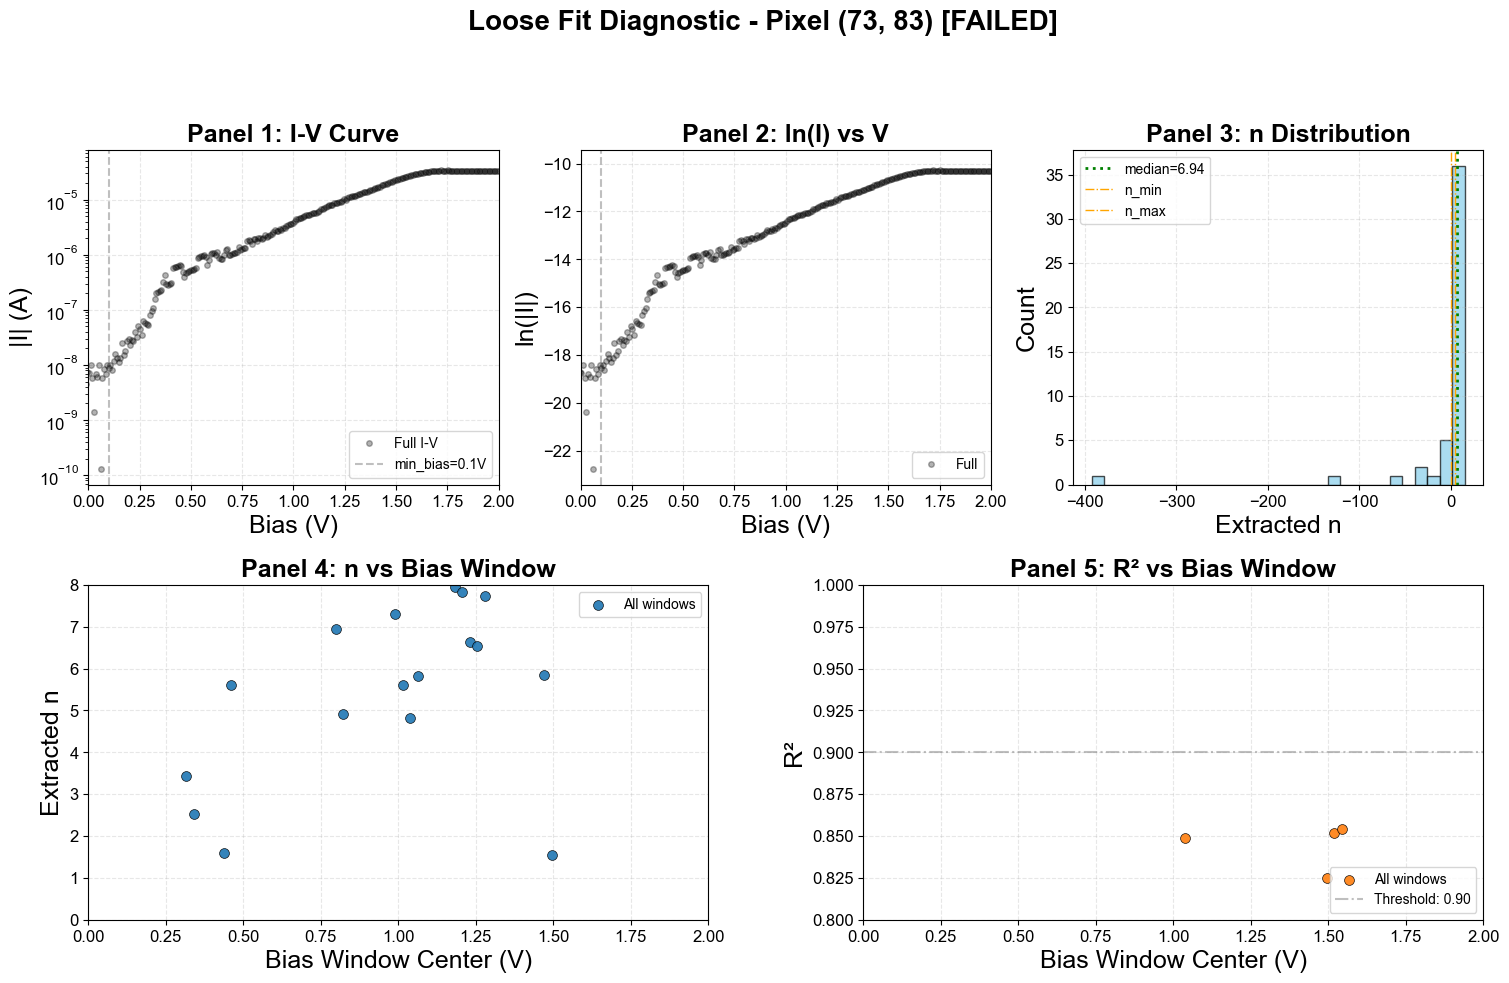

### ❌ FIT FAILED - Pixel (73, 83)

**Reason:** 多階段篩選失敗。通過：0/72

In [23]:
from ivs_tools.physics.sliding_window_fitter import SlidingWindowCheungFitter

fitter_loose = SlidingWindowCheungFitter()
fitter_loose.config.n_min = 0.5
fitter_loose.config.n_max = 5.0
fitter_loose.config.min_r_squared = 0.85
fitter_loose.config.window_size = 30

result_loose = fitter_loose.fit(
    bias=bias,
    current=spec,
    area_cm2=analyzer.area_cm2,
    T=analyzer.T,
    a_star=analyzer.A_star,
    layer_type="multilayer",
    forward_bias_only=True,
    min_forward_bias=0.1
)

plot_loose_fit_diagnostic(fitter_loose, result_loose, (73, 83), bias, spec)

### Step 5: 批量處理

In [11]:

L3_points = [(15, 68), (25, 62), (29, 69), (74, 55), (85, 59), (92, 65)]
L4_points = [(44, 72), (49, 70), (50, 58), (54, 53), (66, 60), (74, 66)]
L5_points = [(60, 80), (60, 76), (61, 76), (70, 74), (81, 79), (87, 83)]
L6_points = [(68, 83), (70, 81), (75, 85), (76, 84), (72, 84), (76, 86)]

layer_points =  {f"L{i}": globals()[f"L{i}_points"] for i in range(3, 7)}
        
df_dict = {}

for layer_names, points in layer_points.items():
    results = analyzer.batch_fit(h5map, pixel_list=points)
    df = analyzer.results_to_dataframe(results)
    df_dict[layer_names] = df


Fitting pixels: 100%|█████████████████████████████████████| 6/6 [00:00<00:00, 123.90it/s]


In [12]:
df_dict['L3']

,x,y,success,n,Rs,phi_b,r_squared,score,fit_range,warning
0,15,68,True,2.402580,17625.914013,0.043371,0.940835,0.667687,"(0.10020041, 0.29258513)",None
1,25,62,True,1.951233,24799.423923,0.054164,0.967147,0.687055,"(0.10020041, 0.29258513)",None
2,29,69,True,2.295690,25846.592881,0.056002,0.956613,0.680971,"(0.10020041, 0.29258513)",None
3,74,55,True,2.607750,18335.407916,0.046746,0.915396,0.652947,"(0.10020041, 0.29258513)",None
4,85,59,True,1.988150,24405.921618,0.058369,0.973185,0.696177,"(0.10020041, 0.29258513)",None
5,92,65,True,2.416617,17847.962408,0.045166,0.957779,0.680788,"(0.10020041, 0.29258513)",None


In [13]:
df_dict['L4']

,x,y,success,n,Rs,phi_b,r_squared,score,fit_range,warning
0,44,72,True,4.091851,3269.145947,0.123736,0.976269,0.716826,"(0.50901818, 0.7014029)",None
1,49,70,True,3.315914,5588.600381,0.166399,0.994397,0.735058,"(0.55711436, 0.74949908)",None
2,50,58,True,4.109739,3848.624687,0.127310,0.986789,0.736656,"(0.48496985, 0.67735481)",None
3,54,53,True,4.063312,3050.466389,0.123661,0.974897,0.730087,"(0.46092176, 0.65330672)",None
4,66,60,True,4.229076,3952.296487,0.121583,0.985621,0.717478,"(0.53306627, 0.72545099)",None
5,74,66,True,2.768172,100363.369547,0.101993,0.940877,0.680715,"(0.10020041, 0.29258513)",None


In [14]:
df_dict['L5']

,x,y,success,n,Rs,phi_b,r_squared,score,fit_range,warning
0,60,80,True,2.352340,12863.988489,0.265789,0.977605,0.688498,"(0.65330672, 0.84569144)",None
1,60,76,True,4.239956,5647.251965,0.170051,0.988824,0.722221,"(0.7014029, 0.89378762)",None
2,61,76,True,4.716039,6542.576986,0.159804,0.960883,0.670919,"(0.79759526, 0.98997998)",None
3,70,74,True,2.952387,9425.796735,0.229990,0.992405,0.720944,"(0.67735481, 0.86973953)",None
4,81,79,True,1.922830,609375.343998,0.181963,0.960554,0.698709,"(0.14829659, 0.34068131)",None
5,87,83,True,3.211469,19705.796507,0.221873,0.963727,0.685187,"(0.65330672, 0.84569144)",None


In [15]:
df_dict['L6']

,x,y,success,n,Rs,phi_b,r_squared,score,fit_range,warning
0,68,83,True,2.135638,56156.761913,0.368763,0.963645,0.673697,"(0.74949908, 0.9418838)",NaN
1,70,81,True,2.068302,33086.957186,0.377707,0.976001,0.720097,"(0.7014029, 0.89378762)",NaN
2,75,85,True,3.938296,11575.900495,0.287536,0.901073,0.581091,"(1.4949901, 1.6873748)",NaN
3,76,84,False,NaN,NaN,NaN,NaN,0.000000,None,多階段篩選失敗。通過：0/72
4,72,84,False,NaN,NaN,NaN,NaN,0.000000,None,多階段篩選失敗。通過：0/72
5,76,86,True,2.866282,14269.196232,0.370382,0.910350,0.594383,"(1.3026052, 1.4949901)",NaN


## Looe batch fit

In [14]:
# %% 建立寬鬆參數的 Analyzer 用於批量處理
from ivs_tools.physics.sliding_window_fitter import FittingConfig
from ivs_tools import SchottkyAnalyzer, ConfigLoader

# 建立寬鬆配置
loose_config = FittingConfig(
    window_size=25,
    step_size=3,
    min_r_squared=0.85,      # 放寬 R²
    n_min=0.5, n_max=5.0,    # 放寬 n
    Rs_min=0, Rs_max=1e10,
    savgol_window=31,
    current_threshold=5e-13,
    layer_type="multilayer"
)

# 建立寬鬆版 analyzer
analyzer_loose = SchottkyAnalyzer(
    area_cm2=ConfigLoader.get_area('cafm_tip_10nm'),
    temperature=300.0,
    a_star=54.0,
    fitting_config=loose_config,  # ← 傳入寬鬆配置
    load_from_yaml=False  # 不從 YAML 載入擬合參數
)

print("🔧 寬鬆版 Analyzer 配置:")
analyzer_loose.print_config_summary()

🔧 寬鬆版 Analyzer 配置:
🔬 SchottkyAnalyzer Configuration
   Area: 7.854e-13 cm²
   Temperature: 300.0 K
   A**: 54.0 A/cm²/K²
   Layer type: multilayer
   V_T: 0.0259 V
   Window: 25 pts
   n range: [0.5, 5.0]
   min R²: 0.85


In [15]:
# %% 用寬鬆版 analyzer 執行批量擬合
L3_points = [(15, 68), (25, 62), (29, 69), (74, 55), (85, 59), (92, 65)]
L4_points = [(44, 72), (49, 70), (50, 58), (54, 53), (66, 60), (74, 66)]
L5_points = [(60, 80), (60, 76), (61, 76), (70, 74), (81, 79), (87, 83)]
L6_points = [(68, 83), (70, 81), (73, 83), (76, 84), (72, 84), (76, 86)]

layer_points = {f"L{i}": globals()[f"L{i}_points"] for i in range(3, 7)}
df_dict_loose = {}

for layer_name, points in layer_points.items():
    print(f"\n🔍 Processing {layer_name} ({len(points)} pixels)...")
    
    results = analyzer_loose.batch_fit(
        h5map, 
        pixel_list=points,
        forward_bias_only=True,
        min_forward_bias=0.1  # 只分析 V > 0.1 V
    )
    
    df = analyzer_loose.results_to_dataframe(results)
    df_dict_loose[layer_name] = df
    
    # 顯示統計
    success_rate = df['success'].mean() * 100
    print(f"   ✅ 成功率：{success_rate:.1f}% ({df['success'].sum()}/{len(df)})")
    
    if df['success'].any():
        print(f"   📊 ΦB: {df[df['success']]['phi_b'].mean():.3f} ± {df[df['success']]['phi_b'].std():.3f} eV")
        print(f"   📊 n:  {df[df['success']]['n'].mean():.2f} ± {df[df['success']]['n'].std():.2f}")


🔍 Processing L3 (6 pixels)...


Fitting pixels: 100%|███████████████████████████████| 6/6 [00:00<00:00, 77.39it/s]


   ✅ 成功率：100.0% (6/6)
   📊 ΦB: 0.051 ± 0.006 eV
   📊 n:  2.28 ± 0.26

🔍 Processing L4 (6 pixels)...


Fitting pixels: 100%|███████████████████████████████| 6/6 [00:00<00:00, 64.81it/s]


   ✅ 成功率：100.0% (6/6)
   📊 ΦB: 0.127 ± 0.021 eV
   📊 n:  3.76 ± 0.59

🔍 Processing L5 (6 pixels)...


Fitting pixels: 100%|███████████████████████████████| 6/6 [00:00<00:00, 53.08it/s]


   ✅ 成功率：100.0% (6/6)
   📊 ΦB: 0.205 ± 0.041 eV
   📊 n:  3.23 ± 1.08

🔍 Processing L6 (6 pixels)...


Fitting pixels: 100%|███████████████████████████████| 6/6 [00:00<00:00, 61.17it/s]

   ✅ 成功率：50.0% (3/6)
   📊 ΦB: 0.372 ± 0.005 eV
   📊 n:  2.36 ± 0.44


In [16]:
df_dict['L3']

,x,y,success,n,Rs,phi_b,r_squared,score,fit_range,warning
0,15,68,True,2.402580,17625.914013,0.043371,0.940835,0.667687,"(0.10020041, 0.29258513)",None
1,25,62,True,1.951233,24799.423923,0.054164,0.967147,0.687055,"(0.10020041, 0.29258513)",None
2,29,69,True,2.295690,25846.592881,0.056002,0.956613,0.680971,"(0.10020041, 0.29258513)",None
3,74,55,True,2.607750,18335.407916,0.046746,0.915396,0.652947,"(0.10020041, 0.29258513)",None
4,85,59,True,1.988150,24405.921618,0.058369,0.973185,0.696177,"(0.10020041, 0.29258513)",None
5,92,65,True,2.416617,17847.962408,0.045166,0.957779,0.680788,"(0.10020041, 0.29258513)",None


In [18]:
df_dict['L4']

,x,y,success,n,Rs,phi_b,r_squared,score,fit_range,warning
0,44,72,True,4.091851,3269.145947,0.123736,0.976269,0.716826,"(0.50901818, 0.7014029)",None
1,49,70,True,3.315914,5588.600381,0.166399,0.994397,0.735058,"(0.55711436, 0.74949908)",None
2,50,58,True,4.109739,3848.624687,0.127310,0.986789,0.736656,"(0.48496985, 0.67735481)",None
3,54,53,True,4.063312,3050.466389,0.123661,0.974897,0.730087,"(0.46092176, 0.65330672)",None
4,66,60,True,4.229076,3952.296487,0.121583,0.985621,0.717478,"(0.53306627, 0.72545099)",None
5,74,66,True,2.768172,100363.369547,0.101993,0.940877,0.680715,"(0.10020041, 0.29258513)",None


In [19]:
df_dict['L5']

,x,y,success,n,Rs,phi_b,r_squared,score,fit_range,warning
0,60,80,True,2.352340,12863.988489,0.265789,0.977605,0.688498,"(0.65330672, 0.84569144)",None
1,60,76,True,4.239956,5647.251965,0.170051,0.988824,0.722221,"(0.7014029, 0.89378762)",None
2,61,76,True,4.716039,6542.576986,0.159804,0.960883,0.670919,"(0.79759526, 0.98997998)",None
3,70,74,True,2.952387,9425.796735,0.229990,0.992405,0.720944,"(0.67735481, 0.86973953)",None
4,81,79,True,1.922830,609375.343998,0.181963,0.960554,0.698709,"(0.14829659, 0.34068131)",None
5,87,83,True,3.211469,19705.796507,0.221873,0.963727,0.685187,"(0.65330672, 0.84569144)",None


In [17]:
df_dict['L6']

,x,y,success,n,Rs,phi_b,r_squared,score,fit_range,warning
0,68,83,True,2.135638,56156.761913,0.368763,0.963645,0.673697,"(0.74949908, 0.9418838)",NaN
1,70,81,True,2.068302,33086.957186,0.377707,0.976001,0.720097,"(0.7014029, 0.89378762)",NaN
2,73,83,False,NaN,NaN,NaN,NaN,0.000000,None,多階段篩選失敗。通過：0/72
3,76,84,False,NaN,NaN,NaN,NaN,0.000000,None,多階段篩選失敗。通過：0/72
4,72,84,False,NaN,NaN,NaN,NaN,0.000000,None,多階段篩選失敗。通過：0/72
5,76,86,True,2.866282,14269.196232,0.370382,0.910350,0.594383,"(1.3026052, 1.4949901)",NaN
